## Trabajo Práctico N° 2: Prediccion de lluvia en Australia

#### Variable de salida (target): 'RainTomorrow'

In [62]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

### 1. EDA

#### Lectura y primera vista del dataset

In [63]:
df = pd.read_csv("weatherAUS_2026C2.csv")
df = df.reset_index(drop=True)

print(f"Cantidad de filas: {df.shape[0]}")
print(f"Cantidad de columnas: {df.shape[1]}")

Cantidad de filas: 145412
Cantidad de columnas: 25


In [64]:
display(df.head())

,Unnamed: 0,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
0,0,2008-12-01,Albury,13.6,22.5,0.6,NaN,NaN,W,45.0,...,23.8,1008.1,1007.2,8.0,NaN,16.8,20.8,No,No,0.0
1,1,2008-12-02,Albury,7.3,25.8,0.0,NaN,NaN,WNW,44.0,...,22.1,1011.1,1007.5,NaN,NaN,18.3,24.6,No,No,0.0
2,2,2008-12-03,Albury,13.2,26.2,0.0,NaN,NaN,WSW,46.0,...,31.5,1007.3,1009.4,NaN,2.0,21.2,23.4,No,No,0.0
3,3,2008-12-04,Albury,10.0,28.8,0.0,NaN,NaN,NE,23.0,...,18.5,1017.6,1012.4,NaN,NaN,17.4,26.3,No,No,1.0
4,4,2008-12-05,Albury,17.4,32.4,1.0,NaN,NaN,W,41.0,...,34.6,1010.9,1005.9,7.0,8.0,17.9,29.1,No,No,0.2


Se detectó una columna "Unnamed: 0" que repite los indices, se elimina para evitar problemas

In [65]:
df = df.drop(columns=["Unnamed: 0"], errors="ignore")
df = df.reset_index(drop=True)

display(df.head())

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
0,2008-12-01,Albury,13.6,22.5,0.6,NaN,NaN,W,45.0,W,...,23.8,1008.1,1007.2,8.0,NaN,16.8,20.8,No,No,0.0
1,2008-12-02,Albury,7.3,25.8,0.0,NaN,NaN,WNW,44.0,NNW,...,22.1,1011.1,1007.5,NaN,NaN,18.3,24.6,No,No,0.0
2,2008-12-03,Albury,13.2,26.2,0.0,NaN,NaN,WSW,46.0,W,...,31.5,1007.3,1009.4,NaN,2.0,21.2,23.4,No,No,0.0
3,2008-12-04,Albury,10.0,28.8,0.0,NaN,NaN,NE,23.0,SE,...,18.5,1017.6,1012.4,NaN,NaN,17.4,26.3,No,No,1.0
4,2008-12-05,Albury,17.4,32.4,1.0,NaN,NaN,W,41.0,ENE,...,34.6,1010.9,1005.9,7.0,8.0,17.9,29.1,No,No,0.2


#### Descripcion general

In [66]:
print("Tipos de datos:")
display(df.dtypes)

print("\nInformación general:")
df.info()

Tipos de datos:


Date                    str
Location                str
MinTemp             float64
MaxTemp             float64
Rainfall            float64
Evaporation         float64
Sunshine            float64
WindGustDir             str
WindGustSpeed       float64
WindDir9am              str
WindDir3pm              str
WindSpeed9am        float64
WindSpeed3pm        float64
Humidity9am         float64
Humidity3pm         float64
Pressure9am         float64
Pressure3pm         float64
Cloud9am            float64
Cloud3pm            float64
Temp9am             float64
Temp3pm             float64
RainToday               str
RainTomorrow            str
RainfallTomorrow    float64
dtype: object


Información general:
<class 'pandas.DataFrame'>
RangeIndex: 145412 entries, 0 to 145411
Data columns (total 24 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Date              145412 non-null  str    
 1   Location          145412 non-null  str    
 2   MinTemp           143928 non-null  float64
 3   MaxTemp           144159 non-null  float64
 4   Rainfall          142152 non-null  float64
 5   Evaporation       82658 non-null   float64
 6   Sunshine          75616 non-null   float64
 7   WindGustDir       135096 non-null  str    
 8   WindGustSpeed     135159 non-null  float64
 9   WindDir9am        134850 non-null  str    
 10  WindDir3pm        141186 non-null  str    
 11  WindSpeed9am      143645 non-null  float64
 12  WindSpeed3pm      142351 non-null  float64
 13  Humidity9am       142759 non-null  float64
 14  Humidity3pm       140907 non-null  float64
 15  Pressure9am       130351 non-null  float64
 16  Pressure3

RainfallTomorrow es una caracteristica que mide en mm la cantidad de lluvia que va a caer mañana, es decir, es informacion del futuro que se relaciona con el target, ya que si es mayor a 1 (umbral del dataset) sabemos que RainTomorrow es 'Si'. Se elimin para evitar fuga de datos.

In [67]:
df = df.drop(columns=["RainfallTomorrow"])

#### Trabajamos con una serie temporal, por lo que vamos a pasar la fecha a formato Date y reordenalo cronologicamente

In [68]:
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

print(f"Fecha mínima: {df['Date'].min().date()}")
print(f"Fecha máxima: {df['Date'].max().date()}")

Fecha mínima: 2007-11-01
Fecha máxima: 2017-06-24


#### Análisis de nulos y duplicados

In [69]:
print("Valores faltantes por columna:")

nulos = pd.DataFrame({
    "Cantidad": df.isnull().sum(),
    "Porcentaje": round(df.isnull().mean()*100,2)
})

display(nulos.sort_values("Porcentaje", ascending=False))

print(f"\nCantidad de registros totalmente nulos:")
print(len(df[df.isna().all(axis=1)])) 

print("\nFilas sin target (RainTomorrow):", df['RainTomorrow'].isnull().sum()) 

print(f"\nFilas duplicadas: {df.duplicated().sum()}")

Valores faltantes por columna:


,Cantidad,Porcentaje
Sunshine,69796,48.00
Evaporation,62754,43.16
Cloud3pm,59336,40.81
Cloud9am,55870,38.42
Pressure9am,15061,10.36
Pressure3pm,15024,10.33
WindDir9am,10562,7.26
WindGustDir,10316,7.09
WindGustSpeed,10253,7.05
Humidity3pm,4505,3.10



Cantidad de registros totalmente nulos:
0

Filas sin target (RainTomorrow): 3259

Filas duplicadas: 0


Se detectaron 3259 sin la variable target. Para el presente análisis se descartarán estas filas debido a que no se puede evaluar ni entrenar supervisado sin etiqueta

In [70]:
df = df.dropna(subset=['RainTomorrow'])
df = df.dropna(how='all')
print(f"Dataset después de eliminar filas con target nulo: {df.shape[0]:,} Registros con {df.shape[1]} características")

print(f"\nValores faltantes por columna despues de eliminar filas con target nulo:")

nulos2 = pd.DataFrame({
    "Cantidad": df.isnull().sum(),
    "Porcentaje": round(df.isnull().mean()*100,2)
})

display(nulos2.sort_values("Porcentaje", ascending=False))

Dataset después de eliminar filas con target nulo: 142,153 Registros con 23 características

Valores faltantes por columna despues de eliminar filas con target nulo:


,Cantidad,Porcentaje
Sunshine,67785,47.68
Evaporation,60812,42.78
Cloud3pm,57076,40.15
Cloud9am,53641,37.73
Pressure9am,14010,9.86
Pressure3pm,13977,9.83
WindDir9am,10009,7.04
WindGustDir,9328,6.56
WindGustSpeed,9268,6.52
WindDir3pm,3776,2.66


#### Conteo de nulos por fila

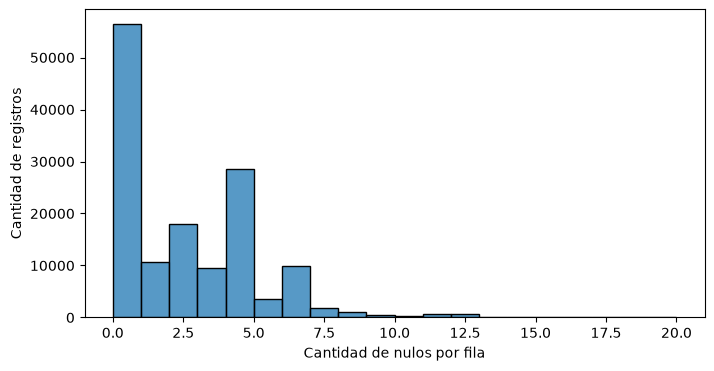


Cantidad de registros por cantidad de nulos por fila:


0     56412
1     10764
2     18023
3      9607
4     28531
5      3639
6      9934
7      1801
8       964
9       393
10      290
11      679
12      757
13      106
14       39
15       26
16       27
17       91
18       49
19       16
20        5
Name: count, dtype: int64

In [71]:
nulos_fila = df.isnull().sum(axis=1)

plt.figure(figsize=(8,4))

sns.histplot(nulos_fila, bins=20)

plt.xlabel("Cantidad de nulos por fila")
plt.ylabel("Cantidad de registros")
plt.show()

print("\nCantidad de registros por cantidad de nulos por fila:")
nulos_fila.value_counts().sort_index()

#### Promedio de nulos por cuidad

In [72]:
(df.groupby("Location").apply(lambda x: x.isnull().mean()*100))

,Date,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
Location,,,,,,,,,,,,,,,,,,,,,
Adelaide,0.0,0.064725,0.064725,2.265372,46.634304,45.048544,0.744337,0.744337,8.381877,0.485437,...,0.161812,0.161812,0.258900,0.226537,100.000000,100.000000,0.161812,0.129450,2.265372,0.0
Albany,0.0,1.956882,1.061360,0.663350,9.253731,16.749585,100.000000,100.000000,8.092869,25.406302,...,1.525705,23.184080,0.829187,0.796020,1.160862,23.018242,1.194030,23.051410,0.663350,0.0
Albury,0.0,0.199336,0.033223,0.664452,100.000000,100.000000,0.332226,0.332226,17.176080,1.362126,...,0.132890,0.132890,0.000000,0.132890,57.441860,53.023256,0.132890,0.132890,0.664452,0.0
AliceSprings,0.0,0.032992,0.032992,0.197954,6.961399,16.859122,1.649621,1.649621,7.588255,0.131970,...,0.098977,0.164962,0.032992,0.098977,10.953481,11.811283,0.000000,0.065985,0.197954,0.0
BadgerysCreek,0.0,0.409976,0.102494,1.742398,100.000000,100.000000,0.546635,0.546635,13.460881,2.049880,...,0.990776,1.059105,4.885548,5.056372,100.000000,100.000000,0.546635,0.683293,1.742398,0.0
Ballarat,0.0,0.033036,0.033036,0.363396,100.000000,100.000000,0.792864,0.792864,3.006277,0.528576,...,0.693756,0.198216,0.792864,0.792864,17.971589,34.390486,0.396432,0.165180,0.363396,0.0
Bendigo,0.0,0.032971,0.032971,0.131883,60.929773,100.000000,1.186944,1.153973,8.011869,1.384768,...,0.164853,0.032971,0.461589,0.296736,31.783712,25.288493,0.065941,0.032971,0.131883,0.0
Brisbane,0.0,0.189873,0.126582,0.917722,0.601266,1.518987,0.474684,0.474684,2.183544,0.854430,...,0.063291,0.284810,0.000000,0.063291,0.031646,0.063291,0.063291,0.284810,0.917722,0.0
Cairns,0.0,0.033478,0.000000,0.803482,11.382658,14.228323,0.602611,0.569133,1.406093,0.133914,...,0.000000,0.000000,0.000000,0.000000,6.193505,6.896552,0.000000,0.000000,0.803482,0.0


#### Posible patron

In [73]:
columnas = ["Evaporation", "Sunshine", "Cloud3pm", "Cloud9am"]

nulos_simultaneos_por_fila = df[columnas].isna().all(axis=1)

resumen_ciudades = nulos_simultaneos_por_fila.groupby(df["Location"]).agg(todas_las_filas_nulas="all",cantidad_filas="size") #True si todas las filas de la ciudad tienen nulos simultáneos en el bloque

ciudades_con_nulos_simultaneos = (resumen_ciudades.loc[resumen_ciudades["todas_las_filas_nulas"], "cantidad_filas"].rename_axis("Ciudad").reset_index(name="Cantidad de filas"))

total_ciudades = df["Location"].nunique()
ciudades_con_nulos = ciudades_con_nulos_simultaneos["Ciudad"].nunique()
porcentaje = ciudades_con_nulos / total_ciudades * 100

print(f"Ciudades con nulos simultaneos: {ciudades_con_nulos} de {total_ciudades} ({porcentaje:.2f}%)")
display(ciudades_con_nulos_simultaneos)

Ciudades con nulos simultaneos: 10 de 49 (20.41%)


,Ciudad,Cantidad de filas
0,BadgerysCreek,2927
1,GoldCoast,2979
2,MountGinini,2906
3,Nhil,1568
4,NorahHead,2928
5,Penrith,2963
6,SalmonGums,2954
7,Tuggeranong,2997
8,Walpole,2818
9,Witchcliffe,2951


#### Probamos tambien con 2 de las 4 columnas

In [74]:
columnas = ["Evaporation", "Sunshine"]

nulos_simultaneos_por_fila = df[columnas].isna().all(axis=1)

resumen_ciudades = nulos_simultaneos_por_fila.groupby(df["Location"]).agg(todas_las_filas_nulas="all",cantidad_filas="size") #True si todas las filas de la ciudad tienen nulos simultáneos en el bloque

ciudades_con_nulos_simultaneos = (resumen_ciudades.loc[resumen_ciudades["todas_las_filas_nulas"], "cantidad_filas"].rename_axis("Ciudad").reset_index(name="Cantidad de filas"))

total_ciudades = df["Location"].nunique()
ciudades_con_nulos = ciudades_con_nulos_simultaneos["Ciudad"].nunique()
porcentaje = ciudades_con_nulos / total_ciudades * 100

print(f"Ciudades con nulos simultaneos: {ciudades_con_nulos} de {total_ciudades} ({porcentaje:.2f}%)")
display(ciudades_con_nulos_simultaneos)

Ciudades con nulos simultaneos: 15 de 49 (30.61%)


,Ciudad,Cantidad de filas
0,Albury,3010
1,BadgerysCreek,2927
2,Ballarat,3027
3,GoldCoast,2979
4,MountGinini,2906
5,Newcastle,2955
6,Nhil,1568
7,NorahHead,2928
8,Penrith,2963
9,SalmonGums,2954


En el histograma original habia un pico marcado en 4 y otro mas pequeño en 2, lo que nos permitió detectar un patron. Al analizar los faltantes por cuidad, nos dimos cuenta que habia varias cuidades en las que se repetian pares de caracteristicas totalmente nulas: "Evaporation" - "Sunshine" y "Cloud3pm" -"Cloud9am". En muchos casos estos dos pares nulos aparecen al mismo tiempo. El 20.41% de las cuidades presenta las 4 caracteristicas juntas al mismo tiempo, mientras que el par "Evaporation" - "Sunshine" aparece totalmente nulo en el 30.61% de ellas. Esto sugiere que dichos atributos no fueron medidos por cuestiones meteorológicas, no se trata de valores faltantes aleatorios sino estructurales.

Volvemos a calcular el histograma pero dejando solo los nulos reales, eliminando los que vengas de una columna 100% nula

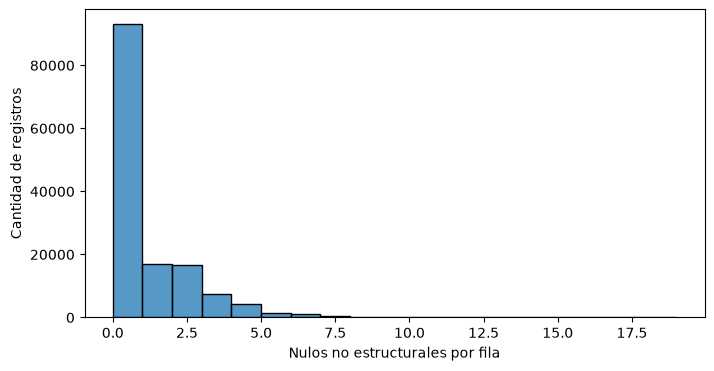

0     93065
1     16893
2     16565
3      7470
4      4183
5      1439
6      1166
7       432
8       149
9        72
10       54
11      294
12      295
13       34
14       20
15       15
16        3
17        3
18        1
Name: count, dtype: int64

In [75]:
caracteristicas = [c for c in df.columns if c not in ['Date', 'Location', 'RainTomorrow', 'RainfallTomorrow']] 
nulos_totales = df[caracteristicas].isnull().sum(axis=1) 

# True si la columna es 100% nula en la ciudad de esa fila
mascara = df.groupby('Location')[caracteristicas].transform(lambda s: s.isnull().all())

# Guardo los nulos que son estructurales (los que son nulos en todas las filas de la ciudad)
nulos_estructurales = mascara.sum(axis=1)

nulos_reales = nulos_totales - nulos_estructurales

plt.figure(figsize=(8,4))
sns.histplot(nulos_reales, bins=range(0, 20))
plt.xlabel("Nulos no estructurales por fila")
plt.ylabel("Cantidad de registros")
plt.show()

nulos_reales.value_counts().sort_index()

#### Eliminacion de filas con nulos: 8 o mas nulos

In [76]:
nulos_por_fila = df.isnull().sum(axis=1)
umbral = 8

filas_eliminar = nulos_por_fila >= umbral

cant_eliminar = filas_eliminar.sum()
cant_total = len(df)
porcentaje = cant_eliminar / cant_total * 100

print(f"Umbral seleccionado: {umbral} o mas valores nulos")
print(f"Filas a eliminar: {cant_eliminar:,}")
print(f"Total de filas: {cant_total:,}")
print(f"Porcentaje eliminado: {porcentaje:.2f}%")

Umbral seleccionado: 8 o mas valores nulos
Filas a eliminar: 3,442
Total de filas: 142,153
Porcentaje eliminado: 2.42%


In [77]:
df = df.loc[~filas_eliminar].copy()
df = df.reset_index(drop=True)

print(f"Filas restantes: {len(df):,}")
print(f"Nuevo tamaño del dataset: {df.shape}")

Filas restantes: 138,711
Nuevo tamaño del dataset: (138711, 23)


Se eliminaron los registros con ocho o más valores faltantes. Este criterio descartó el 2.42% del conjunto de datos, eliminando observaciones con una proporción considerable de información ausente y reduciendo la necesidad de realizar imputaciones sobre una gran cantidad de variables dentro de un mismo registro.

#### Incorporacion de informacion geografica auxiliar

Durante el analisis de valores faltantes observamos que algunas variables presentan faltantes estructurales concentrados en determinadas estaciones meteorologicas, lo que indica que ciertas mediciones nunca fuero registradas en estas ubicaciones. Para poder realizar la imputacion con observaciones climaticamente similares, vamos a incorporar de forma temporal el estado australiano al que pertenece cada Location.
No vamos a obtener la informacion del dataset, sino de informacion geografica conocida. Para no depender de fuentes externas, se construyó manualmente un diccionario que relaciona cada una de las 49 estaciones meteorológicas con su estado correspondiente. La variable 'State' será utilizada únicamente durante el proceso de imputación y posteriormente será eliminada.

In [78]:
state_map = {
    "Albury": "NSW",
    "BadgerysCreek": "NSW",
    "Cobar": "NSW",
    "CoffsHarbour": "NSW",
    "Moree": "NSW",
    "Newcastle": "NSW",
    "NorahHead": "NSW",
    "NorfolkIsland": "External",
    "Penrith": "NSW",
    "Richmond": "NSW",
    "Sydney": "NSW",
    "SydneyAirport": "NSW",
    "WaggaWagga": "NSW",
    "Williamtown": "NSW",
    "Wollongong": "NSW",

    "Canberra": "ACT",
    "Tuggeranong": "ACT",
    "MountGinini": "ACT",

    "Ballarat": "VIC",
    "Bendigo": "VIC",
    "Sale": "VIC",
    "Melbourne": "VIC",
    "MelbourneAirport": "VIC",
    "Mildura": "VIC",
    "Nhil": "VIC",
    "Portland": "VIC",
    "Watsonia": "VIC",
    "Dartmoor": "VIC",

    "Brisbane": "QLD",
    "Cairns": "QLD",
    "GoldCoast": "QLD",
    "Townsville": "QLD",
    "MountIsa": "QLD",

    "AliceSprings": "NT",
    "Darwin": "NT",
    "Katherine": "NT",
    "Uluru": "NT",

    "Adelaide": "SA",
    "MountGambier": "SA",
    "Nuriootpa": "SA",
    "Woomera": "SA",

    "Perth": "WA",
    "PerthAirport": "WA",
    "Albany": "WA",
    "Witchcliffe": "WA",
    "SalmonGums": "WA",
    "Walpole": "WA",
    "PearceRAAF": "WA",

    "Hobart": "TAS",
    "Launceston": "TAS",
}

Incorporamos la columna de estado al dataset

In [79]:
df["State"] = df["Location"].map(state_map)

display(df["State"].value_counts(dropna=False).rename_axis("Estado").reset_index(name="Cantidad de filas"))


,Estado,Cantidad de filas
0,NSW,39554
1,VIC,27999
2,WA,20070
3,SA,12098
4,QLD,12096
5,NT,9244
6,ACT,8487
7,TAS,6203
8,External,2960


### Diseño de caracteristicas temporales

Para no afectar la naturaleza ciclica de los meses y las estaciones, vamos a transformar el mes con la funcion seno y coseno, obteniendo dos variables continuas 'Mes_sin' y 'Mes_cos', que representan la proximidad entre todos los meses del año

In [80]:
df["Mes"] = df["Date"].dt.month

df["Mes_sin"] = np.sin(2*np.pi*df["Mes"]/12)
df["Mes_cos"] = np.cos(2*np.pi*df["Mes"]/12)

meses = (
    df[["Mes", "Mes_sin", "Mes_cos"]]
    .drop_duplicates()
    .sort_values("Mes")
)

display(meses)

,Mes,Mes_sin,Mes_cos
61,1,5.000000e-01,8.660254e-01
92,2,8.660254e-01,5.000000e-01
150,3,1.000000e+00,6.123234e-17
212,4,8.660254e-01,-5.000000e-01
272,5,5.000000e-01,-8.660254e-01
334,6,1.224647e-16,-1.000000e+00
394,7,-5.000000e-01,-8.660254e-01
636,8,-8.660254e-01,-5.000000e-01
878,9,-1.000000e+00,-1.836970e-16
1116,10,-8.660254e-01,5.000000e-01


Eliminamos la columna Mes ya que no la necesitamos para la representacion ciclica

In [81]:
df.drop(columns="Mes", inplace=True)

### Wind direction


In [82]:
df['WindGustDir'].unique()

<StringArray>
[ 'NW', 'ENE', 'SSE',  'SE',   'E',   'S',   'N', 'WNW', 'ESE',  'NE', 'NNE',
 'NNW',  'SW',   'W', 'WSW',   nan, 'SSW']
Length: 17, dtype: str

In [83]:
compass_mapping = {
    'N': 0,   'NNE': 1,  'NE': 2,   'ENE': 3,
    'E': 4,   'ESE': 5,  'SE': 6,   'SSE': 7,
    'S': 8,   'SSW': 9,  'SW': 10,  'WSW': 11,
    'W': 12,  'WNW': 13, 'NW': 14,  'NNW': 15
}

df["WindGustDir_idx"] = df["WindGustDir"].map(compass_mapping)


df["WindGustDir_sin"] = np.sin(2 * np.pi * df["WindGustDir_idx"] / 16)
df["WindGustDir_cos"] = np.cos(2 * np.pi * df["WindGustDir_idx"] / 16)


direcciones_unicas = (
    df[["WindGustDir", "WindGustDir_idx", "WindGustDir_sin", "WindGustDir_cos"]]
    .drop_duplicates()
    .sort_values("WindGustDir_idx")
)

display(direcciones_unicas)

,WindGustDir,WindGustDir_idx,WindGustDir_sin,WindGustDir_cos
10,N,0.0,0.000000e+00,1.000000e+00
23,NNE,1.0,3.826834e-01,9.238795e-01
19,NE,2.0,7.071068e-01,7.071068e-01
1,ENE,3.0,9.238795e-01,3.826834e-01
7,E,4.0,1.000000e+00,6.123234e-17
16,ESE,5.0,9.238795e-01,-3.826834e-01
5,SE,6.0,7.071068e-01,-7.071068e-01
4,SSE,7.0,3.826834e-01,-9.238795e-01
8,S,8.0,1.224647e-16,-1.000000e+00
105,SSW,9.0,-3.826834e-01,-9.238795e-01


### Eliminacion de incosistencias potenciales

Durante el analisis nos dimos cuenta que las variables Rainfall y RainToday presentan valores faltantes en exactamente las mismas observaciones. Una variable es derivada de la otra, imputar ambas de forma independiente podria generar registros inconsistentes (por ejemplo, una precipitación imputada superior a 1 mm acompañada de RainToday = "No"). Como estos registros nulos representan menos del 1% del conjunto de datos se decidio eliminarlos antes de realizar la imputacion.

Primero vamos a mostrar el descubrimiento:

In [84]:
mask_rainfall = df["Rainfall"].isna()
mask_raintoday = df["RainToday"].isna()

coinciden = (mask_rainfall == mask_raintoday).all()

cant_nulos = (mask_rainfall & mask_raintoday).sum()

print(f"Coincidencia de nulos: {coinciden}")
print(f"Cantidad de registros con Rainfall y RainToday nulos: {cant_nulos}")
print(f"Porcentaje del dataset: {cant_nulos / len(df) * 100:.2f}%")

Coincidencia de nulos: True
Cantidad de registros con Rainfall y RainToday nulos: 986
Porcentaje del dataset: 0.71%


Con esto demostrado, pasamos a eliminar estos registros

In [85]:
df = df.loc[~(mask_rainfall & mask_raintoday)].reset_index(drop=True)

print(f"Nuevo tamaño del dataset: {df.shape}")

Nuevo tamaño del dataset: (137725, 29)


### Split temporal

Dado que el conjunto de datos corresponde a una serie temporal, la division entre train y test no se puede hacer de forma aleatoria, ya que estariamos usando informacion del futuro. Ordenamos el dataset cronologicamente, por lo que para dividir, vamos a usar como fecha de corte el 1 de enero de 2016. De esta manera, el conjunto de entrenamiento contiene observaciones desde noviembre de 2007 hasya diciembre de 2015, mientras que el conjunto de prueba abarca desde enero de 2016 hasta junio de 2017.

In [86]:
fecha_corte = pd.Timestamp("2016-01-01")

train = df[df["Date"] < fecha_corte].copy()
test = df[df["Date"] >= fecha_corte].copy()

In [87]:
print("Train")
print(f"Filas: {len(train):,}")
print(f"Desde: {train['Date'].min().date()}")
print(f"Hasta: {train['Date'].max().date()}")


print("Test")
print(f"Filas: {len(test):,}")
print(f"Desde: {test['Date'].min().date()}")
print(f"Hasta: {test['Date'].max().date()}")

Train
Filas: 113,111
Desde: 2007-11-01
Hasta: 2015-12-31
Test
Filas: 24,614
Desde: 2016-01-01
Hasta: 2017-06-24


#### Imputación 

In [88]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

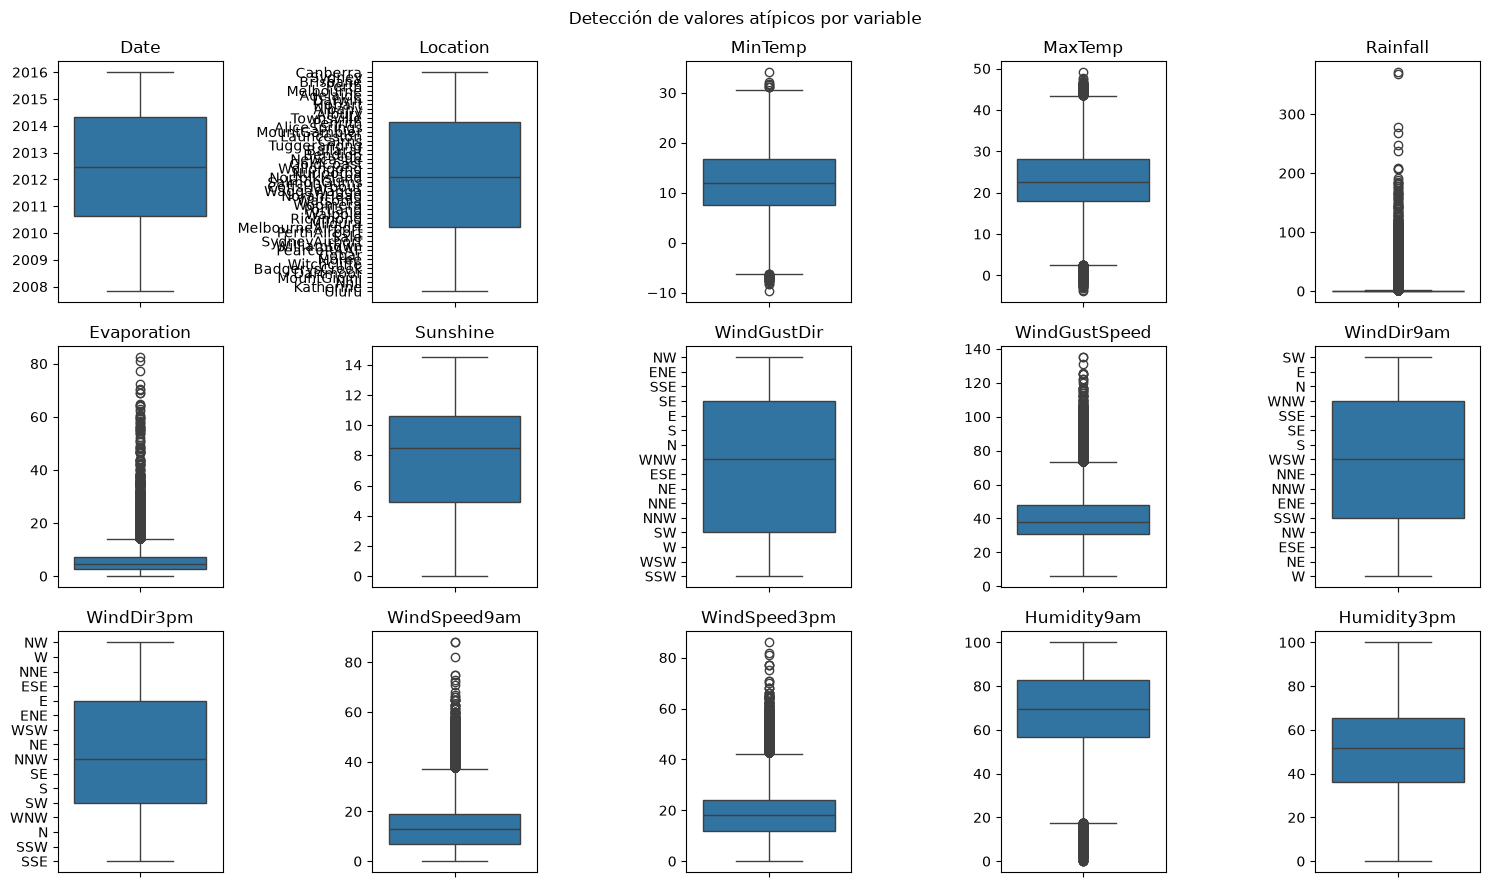

In [89]:
colum = train.columns

fig, axes = plt.subplots(3, 5, figsize=(15, 9))

for ax, col in zip(axes.flat, colum):
    sns.boxplot(y=train[col], ax=ax)
    ax.set_title(col)
    ax.set_ylabel('')

for ax in axes.flat[len(colum):]:
    ax.set_visible(False)

fig.suptitle('Detección de valores atípicos por variable')
plt.tight_layout()
plt.show()

KNN es sencible a outliers

### Opcion 1: convertir outliers en NaN
(Min_temp, Max_temp, Rainfall, Evaporation, windfustspeed, windspeed9am, windspeed3pm, humidity9am)
### Opcion 2: escalar antes de imputar

### Falta similaridad de seno y coseno para windgustdir
